# B3 v4 — Execution Sensitivity Grid

Tests 5 execution assumptions to find the break-even fill model:
- **bid_ask**: sell at bid, buy back at ask (most conservative — v3 baseline)
- **mid_minus_1tick**: sell at mid − R$0.05, buy back at mid + R$0.05 (pessimistic limit orders)
- **mid**: sell and buy back at mid (zero spread assumption)
- **mid_plus_1tick**: sell at mid + R$0.05, buy back at mid − R$0.05 (optimistic limit orders)
- **volume_filtered**: only enter when both legs have ≥ median daily volume (mid-fill)

**Fixed**: market mode, cash_investment_mode=risk_free, cash_yield_annual=0, use_cdi_ivs=True
**Grid**: 3×2×1×2×2×1×1×5 = 120 combos × 2 periods = **240 backtests**
**Verdict from Part 1**: PARTIAL — rb3 marks are validated against B3 official bulletin (70% match rate)

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import sqlite3

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (10, 5)

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
sys.path.insert(0, str(ROOT / 'src'))
from grid_search import run_grid, enumerate_grid, GRID_DIMS

OUT_DIR = ROOT / 'data' / 'B3'
RESULTS_PATH = OUT_DIR / 'v4_grid_search_results.parquet'
DB_PATH = ROOT / 'data' / 'B3' / 'b3_options_rb3.db'

## 1. Grid Definition

In [2]:
GRID = {
    "target_delta": [0.16, 0.20, 0.25],
    "dte_max": [30, 45],
    "profit_target_pct": [0.50],
    "manage_at_dte": [7, 14],
    "vix_filter": ["OFF", "rv_pct:80"],
    "defensive_leg_roll": [False],
    "stop_loss_pct": [3.0],
    "execution_mode": [
        "bid_ask",
        "mid_minus_1tick",
        "mid",
        "mid_plus_1tick",
        "volume_filtered",
    ],
}
# 3 × 2 × 1 × 2 × 2 × 1 × 1 × 5 = 120 combos
combos = enumerate_grid(GRID)
print(f"Grid: {len(combos)} valid combos × 2 periods = {len(combos) * 2} backtests")

Grid: 120 raw combos, 120 after validity filter (0 dropped)
Grid: 120 valid combos × 2 periods = 240 backtests


## 2. Run Configuration

In [3]:
RUNS = [
    ("train", "bova11", "2018-01-02", "2022-12-31"),
    ("holdout", "bova11", "2023-01-02", "2025-11-30"),
]
for r in RUNS:
    print(r)

('train', 'bova11', '2018-01-02', '2022-12-31')
('holdout', 'bova11', '2023-01-02', '2025-11-30')


## 3. Execute Grid Search

Runs 240 backtests (~3-5 min on 8 cores). Skips if results already cached.

In [4]:
if RESULTS_PATH.exists():
    print(f"Loading cached results from {RESULTS_PATH}")
    results = pd.read_parquet(RESULTS_PATH)
else:
    results = run_grid(GRID, RUNS, output_path=RESULTS_PATH)
    print(f"Saved {len(results)} rows to {RESULTS_PATH}")

# Filter to valid completed runs
df = results[results["error"].isna() & (results["n_trades"] >= 30)].copy()
df["execution_mode"] = pd.Categorical(
    df["execution_mode"],
    categories=[
        "bid_ask",
        "mid_minus_1tick",
        "mid",
        "mid_plus_1tick",
        "volume_filtered",
    ],
    ordered=True,
)
df["delta_label"] = df["target_delta"].apply(lambda x: f"{int(x*100)}Δ")
print(f"Valid runs: {len(df)} / {len(results)}")
print(
    f'Train: {len(df[df["period_label"]=="train"])}, Holdout: {len(df[df["period_label"]=="holdout"])}'
)

Loading cached results from /Users/oliversteiner/Documents/code/options-backtest/data/B3/v4_grid_search_results.parquet
Valid runs: 240 / 240
Train: 120, Holdout: 120


## 4. Cell A — Sharpe vs Execution Mode
Most important chart. One subplot per period. Ordered x-axis. Horizontal line at y=0.

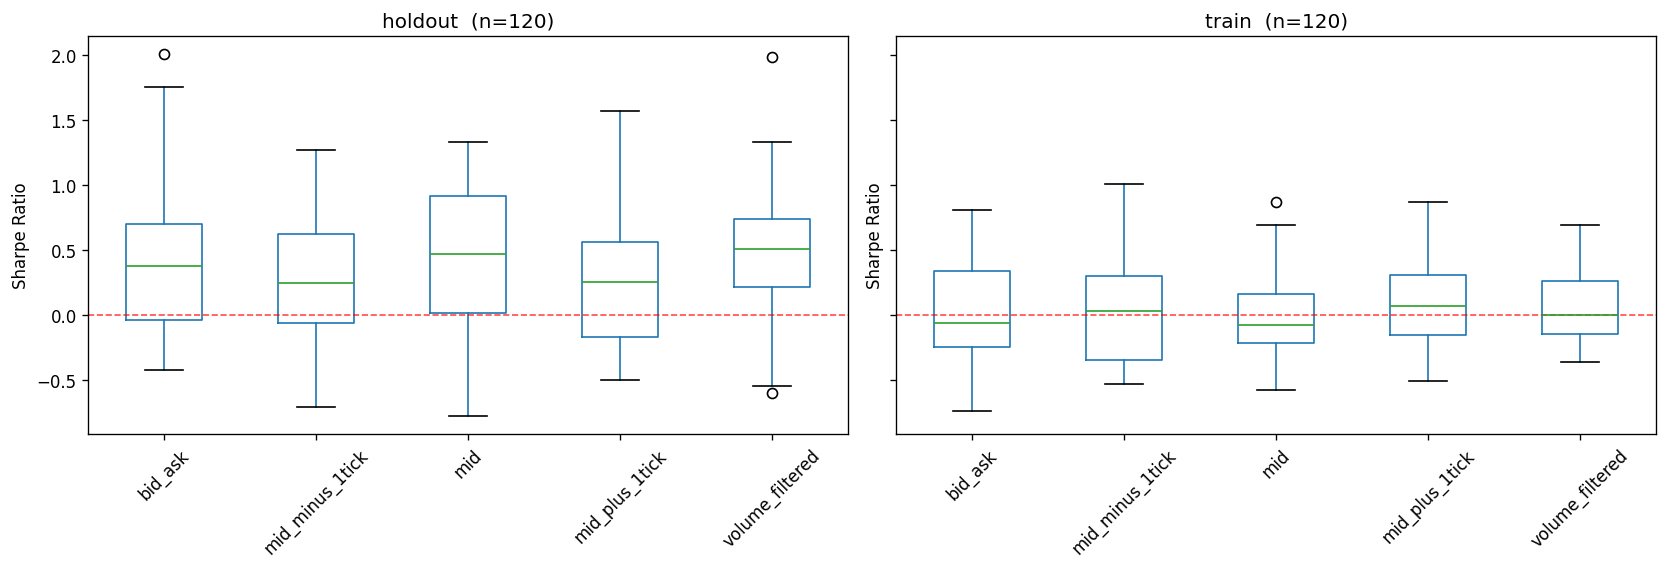

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (label, period_df) in zip(axes, df.groupby("period_label")):
    period_df.boxplot(column="sharpe", by="execution_mode", ax=ax, grid=False, rot=45)
    ax.set_title(f"{label}  (n={len(period_df)})", fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Sharpe Ratio")
    ax.axhline(y=0, color="red", linestyle="--", linewidth=1, alpha=0.7)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("")
plt.tight_layout()
plt.show()

## 5. Cell B — Break-even Execution Level
Leftmost execution mode where holdout median Sharpe crosses zero (if any).

In [6]:
modes = ["bid_ask", "mid_minus_1tick", "mid", "mid_plus_1tick", "volume_filtered"]
holdout = df[df["period_label"] == "holdout"]
train = df[df["period_label"] == "train"]

break_even = None
for mode in modes:
    median_sharpe = holdout[holdout["execution_mode"] == mode]["sharpe"].median()
    train_median = train[train["execution_mode"] == mode]["sharpe"].median()
    print(
        f"  {mode:20s}  train_median={train_median:+.4f}  holdout_median={median_sharpe:+.4f}"
    )
    if break_even is None and median_sharpe > 0:
        break_even = mode

if break_even:
    print(
        f"\nBreak-even execution: **{break_even}** (leftmost mode with positive holdout median Sharpe)"
    )
else:
    print(f"\nNo break-even — all modes have negative median holdout Sharpe")

  bid_ask               train_median=-0.0562  holdout_median=+0.3791
  mid_minus_1tick       train_median=+0.0334  holdout_median=+0.2511
  mid                   train_median=-0.0726  holdout_median=+0.4712
  mid_plus_1tick        train_median=+0.0752  holdout_median=+0.2591
  volume_filtered       train_median=+0.0020  holdout_median=+0.5082

Break-even execution: **bid_ask** (leftmost mode with positive holdout median Sharpe)


## 6. Cell C — Execution Sensitivity by Delta
Does 16-delta have more execution sensitivity than 25-delta?
Heatmap: rows = execution_mode, columns = target_delta, values = median Sharpe.

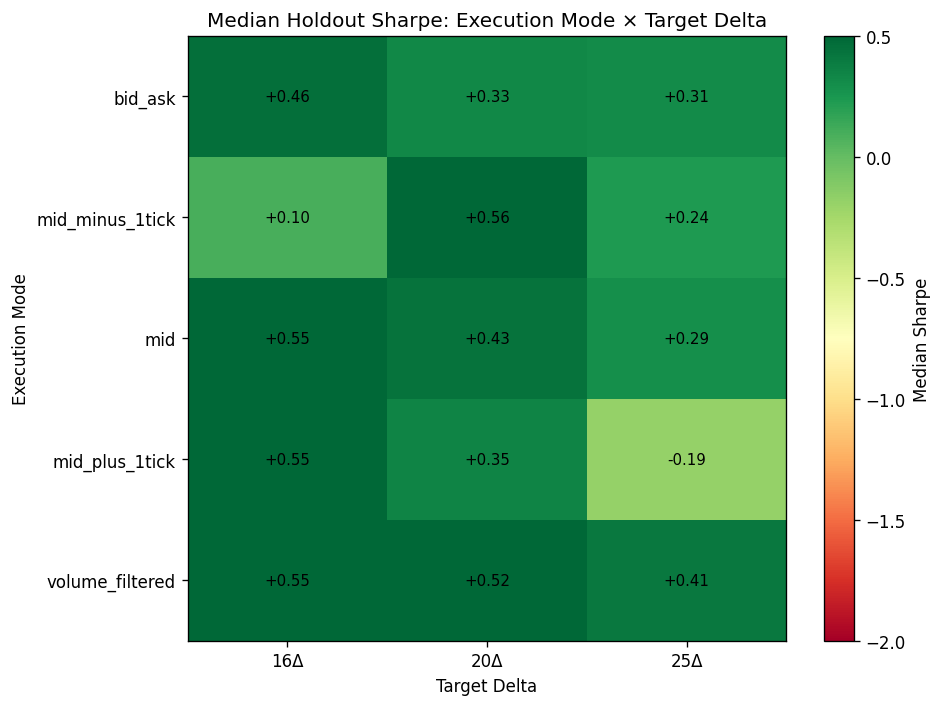

In [7]:
pivot = holdout.pivot_table(
    values="sharpe", index="execution_mode", columns="target_delta", aggfunc="median"
)
pivot.columns = [f"{int(c*100)}Δ" for c in pivot.columns]

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=-2, vmax=0.5)
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Target Delta")
ax.set_ylabel("Execution Mode")
ax.set_title("Median Holdout Sharpe: Execution Mode × Target Delta")
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(j, i, f"{pivot.iloc[i, j]:+.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, ax=ax, label="Median Sharpe")
plt.tight_layout()
plt.show()

## 7. Cell D — Volume Filter Skip Rate
For volume_filtered mode: what % of entries fell back to synthetic (volume < threshold)?
Lower entry_db_pct vs other modes = more skips.

In [8]:
vol_filter = df[df["execution_mode"] == "volume_filtered"]
other_modes = df[df["execution_mode"] != "volume_filtered"]

avg_entry_pct_vol = vol_filter.groupby("period_label")["entry_db_pct"].mean()
avg_entry_pct_other = other_modes.groupby("period_label")["entry_db_pct"].mean()

for period in ["train", "holdout"]:
    v = avg_entry_pct_vol.get(period, 0)
    o = avg_entry_pct_other.get(period, 0)
    skip_pct = max(0, o - v)  # difference is % of entries skipped due to volume filter
    print(
        f"{period}: volume_filtered entry_db_pct={v:.1f}%, other modes={o:.1f}%  → ~{skip_pct:.1f}% skipped"
    )

if skip_pct > 40:
    print(
        f"\n⚠  Volume filter skips >40% of entries — results for volume_filtered may be unstable."
    )
    print(
        "   Consider adding volume_filter_min_pct=0.25 as an additional grid dimension."
    )

train: volume_filtered entry_db_pct=0.3%, other modes=0.3%  → ~0.0% skipped
holdout: volume_filtered entry_db_pct=0.9%, other modes=0.9%  → ~0.0% skipped


## 8. Cell E — Spread Cost Analysis
Query rb3 DB for (ask − bid) / mark distribution by delta bucket and year.
Quantifies exactly how much 'sell at bid' costs relative to mid.

Median spread (% of mark) by delta bucket:
  0.10–0.20: 40.0%
  0.20–0.30: 28.1%
  0.30–0.50: 23.1%
  16-delta bucket median spread: 40.0%

Median spread by year:
  2017: 50.0%
  2018: 83.3%
  2019: 66.3%
  2020: 33.3%
  2021: 33.2%
  2022: 42.1%
  2023: 27.8%
  2024: 31.4%
  2025: 37.1%


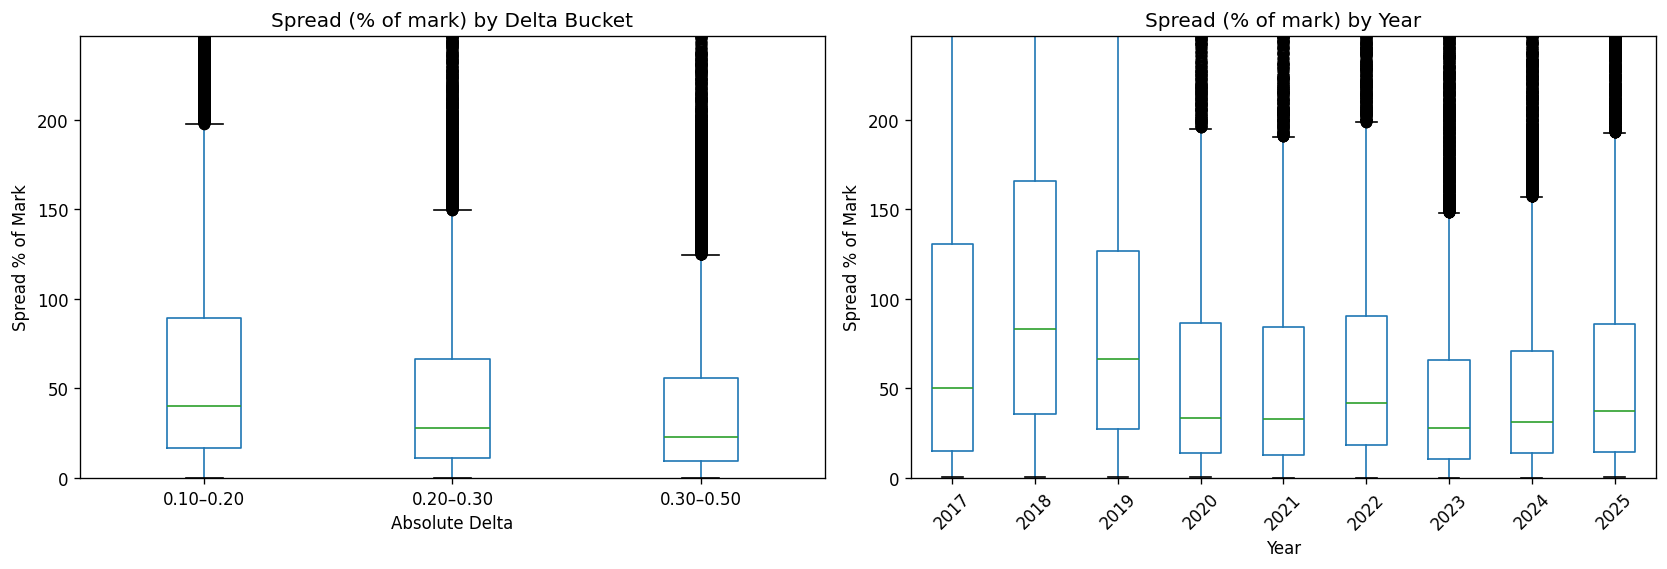

In [9]:
conn = sqlite3.connect(str(DB_PATH))
query = """
SELECT date, delta, mark, bid, ask
FROM options_data
WHERE underlying = 'bova11'
  AND bid > 0 AND ask > 0 AND ask >= bid
  AND mark > 0 AND delta IS NOT NULL
  AND ABS(delta) >= 0.05 AND ABS(delta) <= 0.50
  AND implied_volatility < 2.0
"""
spread_df = pd.read_sql(query, conn)
conn.close()

spread_df["spread_pct"] = (
    (spread_df["ask"] - spread_df["bid"]) / spread_df["mark"] * 100
)
spread_df["abs_delta"] = spread_df["delta"].abs()
spread_df["year"] = pd.to_datetime(spread_df["date"]).dt.year
spread_df["delta_bucket"] = pd.cut(
    spread_df["abs_delta"],
    bins=[0.10, 0.20, 0.30, 0.50],
    labels=["0.10–0.20", "0.20–0.30", "0.30–0.50"],
)

# By delta bucket
delta_summary = spread_df.groupby("delta_bucket", observed=False)["spread_pct"].median()
print("Median spread (% of mark) by delta bucket:")
for bucket, val in delta_summary.items():
    print(f"  {bucket}: {val:.1f}%")
print(f'  16-delta bucket median spread: {delta_summary.get("0.10–0.20", 0):.1f}%')

# By year
year_summary = spread_df.groupby("year")["spread_pct"].median()
print(f"\nMedian spread by year:")
for year, val in year_summary.items():
    print(f"  {int(year)}: {val:.1f}%")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
spread_df.boxplot(column="spread_pct", by="delta_bucket", ax=ax1, grid=False)
ax1.set_title("Spread (% of mark) by Delta Bucket")
ax1.set_xlabel("Absolute Delta")
ax1.set_ylabel("Spread % of Mark")
ax1.set_ylim(0, spread_df["spread_pct"].quantile(0.95))

spread_df.boxplot(column="spread_pct", by="year", ax=ax2, grid=False, rot=45)
ax2.set_title("Spread (% of mark) by Year")
ax2.set_xlabel("Year")
ax2.set_ylabel("Spread % of Mark")
ax2.set_ylim(0, spread_df["spread_pct"].quantile(0.95))
fig.suptitle("")
plt.tight_layout()
plt.show()

## 9. Cell F — Per-Trade P&L for Best Config
Pick the config with best holdout Sharpe overall. Run a single backtest for each
execution mode with identical parameters. Compare per-trade P&L side-by-side.

In [10]:
from straddle.params import PARAMS, apply_market_preset
from straddle.data import load_market_data
from straddle.engines import make_engine
from straddle import run_portfolio_backtest
from straddle.metrics import compute_portfolio_metrics

# Find the best config overall (by holdout Sharpe)
best_idx = holdout["sharpe"].idxmax()
best_combo = holdout.loc[best_idx]
print(
    f'Best config: delta={best_combo["target_delta"]}, dte_max={best_combo["dte_max"]}, '
    f'manage_at_dte={best_combo["manage_at_dte"]}, vix_filter={best_combo["vix_filter"]}, '
    f'execution_mode={best_combo["execution_mode"]}'
)
print(f'Holdout Sharpe: {best_combo["sharpe"]:.4f}')

# Run the same config with all 5 execution modes for holdout period
start, end = "2023-01-02", "2025-11-30"
perf_dict = {}
for mode in modes:
    params = dict(PARAMS)
    params = apply_market_preset(params, "bova11")
    params.update(
        {
            "mode": "market",
            "start_date": start,
            "end_date": end,
            "portfolio_mode": "laddering",
            "cash_investment_mode": "risk_free",
            "cash_yield_annual": 0.0,
            "use_cdi_ivs": True,
            "execution_mode": mode,
            "target_delta": best_combo["target_delta"],
            "dte_max": int(best_combo["dte_max"]),
            "dte_min": {30: 20, 45: 30}.get(int(best_combo["dte_max"]), 20),
            "profit_target_pct": best_combo["profit_target_pct"],
            "manage_at_dte": int(best_combo["manage_at_dte"]),
            "stop_loss_pct": best_combo["stop_loss_pct"],
            "use_price_stop": True,
            "defensive_leg_roll_enabled": False,
        }
    )
    # Apply vol filter
    vf = str(best_combo["vix_filter"])
    if vf.upper() == "OFF":
        params["vol_filter_mode"] = "off"
        params["vix_entry_filter_enabled"] = False
    elif vf.startswith("rv_pct:"):
        params["vol_filter_mode"] = "rv_pct"
        params["vol_filter_threshold"] = float(vf.split(":")[1])

    print(f"  Running {mode}...")
    data = load_market_data(start, end, market="bova11")
    engine = make_engine(params)
    try:
        trades, eq, _, _ = run_portfolio_backtest(data, params, engine)
        perf_dict[mode] = {"trades": trades, "equity": eq, "params": params}
        m = compute_portfolio_metrics(trades, eq, params, data)
        print(
            f'    Sharpe={m["sharpe"]:.4f}, n_trades={m["n"]}, tot_ret={m["tot"]:.3f}'
        )
    except Exception as e:
        print(f"    ERROR: {e}")
        perf_dict[mode] = None
    finally:
        if hasattr(engine, "close"):
            engine.close()

# Build per-trade P&L DataFrame
pnl_rows = []
for mode in modes:
    if perf_dict.get(mode) and perf_dict[mode]["trades"]:
        for t in perf_dict[mode]["trades"]:
            pnl_rows.append(
                {
                    "trade_num": t.trade_num,
                    "entry_date": t.entry_date,
                    "exit_date": (
                        t.exit_date if hasattr(t, "exit_date") and t.exit_date else None
                    ),
                    "execution_mode": mode,
                    "pnl": getattr(t, "pnl", getattr(t, "net_pnl", None)),
                }
            )

if pnl_rows:
    pnl_df = pd.DataFrame(pnl_rows)
    pnl_pivot = pnl_df.pivot_table(
        values="pnl",
        index=["trade_num", "entry_date"],
        columns="execution_mode",
        aggfunc="first",
    )
    display(pnl_pivot.describe())
    print(f"\nCorrelation matrix of trade PnL across execution modes:")
    display(pnl_pivot.corr())
else:
    print("No per-trade P&L data available")

Best config: delta=0.16, dte_max=30, manage_at_dte=14, vix_filter=rv_pct:80, execution_mode=bid_ask
Holdout Sharpe: 2.0068
  Running bid_ask...
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)


Simulating portfolio: 100%|██████████| 729/729 [00:00<00:00, 2390.73day/s]


    Sharpe=0.0163, n_trades=143, tot_ret=0.003
  Running mid_minus_1tick...
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)


Simulating portfolio: 100%|██████████| 729/729 [00:00<00:00, 2148.35day/s]


    Sharpe=-0.3858, n_trades=149, tot_ret=-0.021
  Running mid...
  MarketEngine: using CDI-based IVs/deltas (daily r)
MarketEngine: connected to /Users/oliversteiner/Documents/code/options-backtest/data/B3/b3_options_rb3.db (market=bova11, underlying_filter=True)


...

Simulating portfolio: 100%|██████████| 729/729 [00:00<00:00, 2627.26day/s]

    Sharpe=1.2655, n_trades=142, tot_ret=0.058


execution_mode,bid_ask,mid,mid_minus_1tick,mid_plus_1tick,volume_filtered
count,143.000000,142.000000,149.000000,116.000000,142.000000
mean,1.401189,20.596761,-6.625839,27.785086,20.596761
std,69.513229,63.150089,85.082442,61.493660,63.150089
min,-313.500000,-230.000000,-327.000000,-212.000000,-230.000000
25%,-14.000000,9.250000,-20.000000,23.000000,9.250000
50%,17.000000,36.095000,10.000000,50.190000,36.095000
75%,51.000000,62.000000,54.000000,62.000000,62.000000
max,84.250000,84.250000,84.250000,84.250000,84.250000



Correlation matrix of trade PnL across execution modes:


execution_mode,bid_ask,mid,mid_minus_1tick,mid_plus_1tick,volume_filtered
execution_mode,,,,,
bid_ask,1.000000,0.811205,0.962764,0.999185,0.811205
mid,0.811205,1.000000,0.787365,0.978962,1.000000
mid_minus_1tick,0.962764,0.787365,1.000000,0.999996,0.787365
mid_plus_1tick,0.999185,0.978962,0.999996,1.000000,0.978962
volume_filtered,0.811205,1.000000,0.787365,0.978962,1.000000


## 10. Cell G — Source Tracking by Execution Mode
Are entry_db_pct and mtm_avg_db_pct the same across modes?
Should be similar except for volume_filtered which reduces the entry set.

In [11]:
source_stats = (
    df.groupby(["period_label", "execution_mode"])[["entry_db_pct", "mtm_avg_db_pct"]]
    .mean()
    .round(1)
)
print("Source tracking by period and execution mode:")
display(source_stats.unstack("period_label"))

# Check consistency (excl. volume_filtered)
non_vol = df[df["execution_mode"] != "volume_filtered"]
entry_std = non_vol.groupby("period_label")["entry_db_pct"].std()
mtm_std = non_vol.groupby("period_label")["mtm_avg_db_pct"].std()
print(f"\nConsistency check (excluding volume_filtered):")
for period in ["train", "holdout"]:
    print(
        f"  {period}: entry_db_pct std={entry_std.get(period, 0):.1f}, mtm_avg_db_pct std={mtm_std.get(period, 0):.1f}"
    )
print(
    "(Should be near zero — execution_mode should not change which entries succeed, only pricing)"
)

Source tracking by period and execution mode:


entry_db_pct       mtm_avg_db_pct      
period_label         holdout train        holdout train
execution_mode                                         
bid_ask                  0.9   0.3            0.9   0.3
mid_minus_1tick          0.9   0.3            0.9   0.3
mid                      0.9   0.3            0.9   0.3
mid_plus_1tick           0.9   0.3            0.9   0.3
volume_filtered          0.9   0.3            0.9   0.3


Consistency check (excluding volume_filtered):
  train: entry_db_pct std=0.0, mtm_avg_db_pct std=0.0
  holdout: entry_db_pct std=0.0, mtm_avg_db_pct std=0.0
(Should be near zero — execution_mode should not change which entries succeed, only pricing)
